# Objective 2 - Weekly sales forecasting

Forecasts eTech's weekly product revenue and compares a set of models against baselines
that cost nothing to run.

**The data.** `01_sales_preprocessing.ipynb` produced a weekly series of 243 ISO weeks
(3 Jan 2022 - 24 Aug 2026) with service lines removed, so this is product revenue only.

**The split.** 80% train / 20% test, taken in time order, never at random - a random split
would let the model see 2026 while predicting 2025.

**The framing.** Every model here stands at the end of the training period and forecasts the
whole test block *blind*. It never sees a test actual, not even from the week before. That
rules out `revenue_lag1` and `revenue_roll4`, which need recent actuals - they are available
only in a one-week-ahead setup, which is a different and much easier problem.

**Scoring.** MAE, RMSE and WAPE. Not MAPE: the quietest test week takes about RM 41,000 against
a typical RM 110,000, and percentage error on thin weeks dominates the average.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")

train_in = pd.read_csv("data/processed/train_weekly.csv", parse_dates=["weekStart"])
test_in  = pd.read_csv("data/processed/test_weekly.csv",  parse_dates=["weekStart"])

weekly = (pd.concat([train_in, test_in], ignore_index=True)
            .sort_values("weekStart").reset_index(drop=True))

assert (weekly.weekStart.diff().dropna().dt.days == 7).all(), "series is not contiguous weekly"
print(f"{len(weekly)} weeks  {weekly.weekStart.min():%Y-%m-%d} -> {weekly.weekStart.max():%Y-%m-%d}")

243 weeks  2022-01-03 -> 2026-08-24


## The 80/20 split

Chronological. The cut falls in mid-September 2025, so the test block runs from late September 2025
to the end of August 2026. That block holds something the training period never does: in **January
2026 the shop's product range changes** (every product line except laptops moves to new models, see
`01_sales_preprocessing.ipynb`, step 4), and the sales mix changes with it. Every model below
forecasts across that change without having seen one, which is the honest test.

In [2]:
cut = int(len(weekly) * 0.8)
train, test = weekly.iloc[:cut].copy(), weekly.iloc[cut:].copy()
y_true = test.revenue.to_numpy()

print(f"TRAIN {len(train):3d} weeks  {train.weekStart.min():%Y-%m-%d} -> {train.weekStart.max():%Y-%m-%d}")
print(f"TEST  {len(test):3d} weeks  {test.weekStart.min():%Y-%m-%d} -> {test.weekStart.max():%Y-%m-%d}")
print()
print(f"train revenue  min RM {train.revenue.min():>9,.0f}   max RM {train.revenue.max():>9,.0f}")
print(f"test  revenue  min RM {test.revenue.min():>9,.0f}   max RM {test.revenue.max():>9,.0f}")
print()
print(f"test weeks below the lowest week ever seen in training: "
      f"{(y_true < train.revenue.min()).sum()} of {len(test)}")

TRAIN 194 weeks  2022-01-03 -> 2025-09-15
TEST   49 weeks  2025-09-22 -> 2026-08-24

train revenue  min RM    48,962   max RM   291,286
test  revenue  min RM    40,630   max RM   214,505

test weeks below the lowest week ever seen in training: 2 of 49


### Why that last number decides which models can work

Two test weeks are quieter than *any* week in the training data.

A tree-based model predicts the mean of the training values that land in a leaf, so its
output can never go below the smallest target it was trained on. On a falling series those
weeks are unreachable for it, whatever the tuning.

The usual fix is to give the trees a stationary target: divide out the trend, let the tree
model what is left, then multiply the trend back in. Both versions are run below so the
difference is measured rather than asserted.

In [3]:
results = []
predictions = {}

def evaluate(name, predicted, note=""):
    p = np.asarray(predicted, dtype=float)
    err = y_true - p
    results.append({
        "model": name,
        "MAE":   np.abs(err).mean(),
        "RMSE":  np.sqrt((err ** 2).mean()),
        "WAPE%": np.abs(err).sum() / y_true.sum() * 100,
        "note":  note,
    })
    predictions[name] = p
    return p

## Baselines

If a model cannot beat these, it has not earned its place in the report.

In [4]:
evaluate("Naive (last train week)",
         np.repeat(train.revenue.iloc[-1], len(test)), "flat line")

evaluate("Mean of last 26 weeks",
         np.repeat(train.revenue.tail(26).mean(), len(test)), "flat line")

evaluate("Seasonal naive (lag 52)",
         test.revenue_lag52.to_numpy(), "same week, last year")

log_trend = np.polyfit(train.t, np.log(train.revenue), 1)
evaluate("Log-linear trend",
         np.exp(np.polyval(log_trend, test.t.to_numpy())), "the bar to beat")

print(pd.DataFrame(results).to_string(index=False))

                  model      MAE     RMSE  WAPE%                 note
Naive (last train week) 34,695.6 44,347.5   32.5            flat line
  Mean of last 26 weeks 32,843.2 41,810.9   30.8            flat line
Seasonal naive (lag 52) 33,176.5 45,910.0   31.1 same week, last year
       Log-linear trend 32,956.0 41,224.6   30.9      the bar to beat


## Features a forecaster is actually allowed

Only things knowable before the test period starts:

- `t` - the week index, which carries the trend
- `m_2 ... m_12` - month of the week's Thursday, which carries seasonality
- `revenue_lag52` - the same week a year earlier

`revenue_lag52` costs 52 training rows, because the first year of the series has no prior
year to point at. Both feature sets are fitted so the trade is measured, not guessed.

In [5]:
MONTHS = [f"m_{i}" for i in range(2, 13)]

FEATURES_A = ["t"] + MONTHS                    # keeps every training week
FEATURES_B = ["t", "revenue_lag52"] + MONTHS   # richer, but drops the first 52 weeks

train_b = train.dropna(subset=["revenue_lag52"])

Xa, ya, Xa_test = train[FEATURES_A].to_numpy(), train.revenue.to_numpy(), test[FEATURES_A].to_numpy()
Xb, yb, Xb_test = train_b[FEATURES_B].to_numpy(), train_b.revenue.to_numpy(), test[FEATURES_B].to_numpy()

print(f"feature set A (no lag52): {len(train)} training weeks")
print(f"feature set B (lag52)   : {len(train_b)} training weeks  <- 52 lost to the lag")

feature set A (no lag52): 194 training weeks
feature set B (lag52)   : 142 training weeks  <- 52 lost to the lag


In [6]:
evaluate("Linear regression",
         LinearRegression().fit(Xa, ya).predict(Xa_test), "t + season")

evaluate("Ridge",
         Ridge(alpha=1.0).fit(Xa, ya).predict(Xa_test), "t + season")

evaluate("Ridge (log target)",
         np.exp(Ridge(alpha=1.0).fit(Xa, np.log(ya)).predict(Xa_test)),
         "multiplicative decline")

evaluate("Ridge + lag52",
         Ridge(alpha=1.0).fit(Xb, yb).predict(Xb_test), "142 training weeks")

evaluate("Ridge + lag52 (log)",
         np.exp(Ridge(alpha=1.0).fit(Xb, np.log(yb)).predict(Xb_test)), "142 training weeks")

print(f"{len(results)} models scored so far")

9 models scored so far


## The tree models, run both ways

`Random Forest (raw)` is the version most projects reach for first. The cell below reports
the lowest number it is capable of producing, next to what the shop actually took.

In [7]:
trend_train = np.exp(np.polyval(log_trend, train.t.to_numpy()))
trend_test  = np.exp(np.polyval(log_trend, test.t.to_numpy()))

rf_raw = RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE).fit(Xa, ya)
raw_pred = evaluate("Random Forest (raw)", rf_raw.predict(Xa_test),
                    "cannot go below its training floor")

rf_det = RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE).fit(Xa, ya / trend_train)
evaluate("Random Forest (detrended)", rf_det.predict(Xa_test) * trend_test, "trend divided out")

gb = GradientBoostingRegressor(random_state=RANDOM_STATE).fit(Xa, ya / trend_train)
evaluate("Gradient Boosting (detrended)", gb.predict(Xa_test) * trend_test, "trend divided out")

print(f"lowest training week          RM {train.revenue.min():>9,.0f}")
print(f"lowest Random Forest forecast RM {raw_pred.min():>9,.0f}   <- its floor")
print(f"lowest week the shop took     RM {y_true.min():>9,.0f}")
print()
print(f"weeks the shop fell below the training floor : {(y_true < train.revenue.min()).sum()}")
print(f"weeks the raw forest forecast did            : {(raw_pred < train.revenue.min()).sum()}")

lowest training week          RM    48,962
lowest Random Forest forecast RM   101,602   <- its floor
lowest week the shop took     RM    40,630

weeks the shop fell below the training floor : 2
weeks the raw forest forecast did            : 0


## Results

In [8]:
table = pd.DataFrame(results).sort_values("WAPE%").reset_index(drop=True)
table.index += 1
display(table)

,model,MAE,RMSE,WAPE%,note
1,Linear regression,"29,348.6","36,368.6",27.5,t + season
2,Ridge,"29,661.6","36,788.0",27.8,t + season
3,Ridge (log target),"29,993.1","36,993.4",28.1,multiplicative decline
4,Ridge + lag52,"30,320.2","36,565.2",28.4,142 training weeks
5,Ridge + lag52 (log),"30,435.8","36,807.9",28.6,142 training weeks
6,Random Forest (raw),"30,813.1","36,819.6",28.9,cannot go below its training floor
7,Gradient Boosting (detrended),"31,241.7","36,312.4",29.3,trend divided out
8,Random Forest (detrended),"31,335.4","36,148.8",29.4,trend divided out
9,Mean of last 26 weeks,"32,843.2","41,810.9",30.8,flat line
10,Log-linear trend,"32,956.0","41,224.6",30.9,the bar to beat


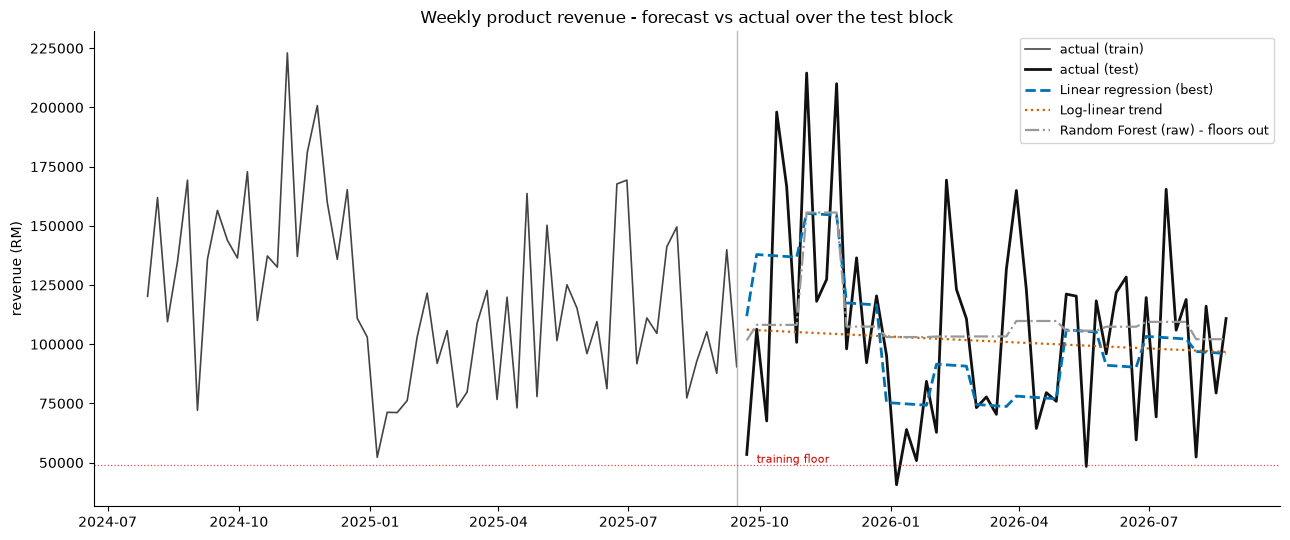

In [9]:
best = table.iloc[0]["model"]
baseline = "Log-linear trend"

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(train.weekStart.tail(60), train.revenue.tail(60), color="#444", lw=1.2, label="actual (train)")
ax.plot(test.weekStart, y_true, color="#111", lw=2.0, label="actual (test)")
ax.plot(test.weekStart, predictions[best], lw=2.0, ls="--", color="#0072B2", label=f"{best} (best)")
ax.plot(test.weekStart, predictions[baseline], lw=1.6, ls=":", color="#D55E00", label=baseline)
ax.plot(test.weekStart, predictions["Random Forest (raw)"], lw=1.6, ls="-.", color="#999",
        label="Random Forest (raw) - floors out")
ax.axvline(train.weekStart.iloc[-1], color="#bbb", lw=1)
ax.axhline(train.revenue.min(), color="#cc0000", lw=0.9, ls=":", alpha=0.7)
ax.text(test.weekStart.iloc[1], train.revenue.min() * 1.02, "training floor",
        color="#cc0000", fontsize=8)
ax.set_title("Weekly product revenue - forecast vs actual over the test block")
ax.set_ylabel("revenue (RM)")
ax.legend(loc="upper right", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## The same forecast, read monthly

Weekly numbers for a shop this size are volatile - one rig build moves a week by a fifth.
Adding the weekly forecasts up into months averages that out, and is the fairer view of
whether the model is useful for planning. The model is unchanged; only the reporting bucket is.

In [10]:
monthly = (pd.DataFrame({"weekStart": test.weekStart.to_numpy(),
                         "actual": y_true,
                         "forecast": predictions[best]})
             .assign(month=lambda d: d.weekStart.dt.to_period("M").astype(str))
             .groupby("month")[["actual", "forecast"]].sum())
monthly = monthly.iloc[1:-1]   # first and last months are only part-covered by whole test weeks
monthly["error"] = monthly.forecast - monthly.actual
monthly["error%"] = monthly.error / monthly.actual * 100

wape_m = monthly.error.abs().sum() / monthly.actual.sum() * 100
display(monthly)
print(f"{best}: monthly WAPE {wape_m:.1f}% over the {len(monthly)} fully covered test months")

,actual,forecast,error,error%
month,,,,
2025-10,"532,941.0","548,679.9","15,738.9",3.0
2025-11,"669,975.0","619,481.2","-50,493.8",-7.5
2025-12,"542,366.0","543,400.2","1,034.2",0.2
2026-01,"239,761.0","298,628.9","58,867.9",24.6
2026-02,"466,007.0","364,602.5","-101,404.5",-21.8
2026-03,"517,902.0","374,533.4","-143,368.6",-27.7
2026-04,"342,940.0","309,495.9","-33,444.1",-9.8
2026-05,"408,169.0","422,334.5","14,165.5",3.5
2026-06,"525,359.0","466,066.7","-59,292.3",-11.3


Linear regression: monthly WAPE 11.2% over the 10 fully covered test months


## Every model, scored by month (3 Nov 2026)

The staff console and the report show the forecast by month only. Each model's weekly test
predictions are added up into the same 10 fully covered test months as above (October 2025 to
July 2026) and scored with MAE, RMSE and WAPE, plus its single worst month. Nothing is refitted:
these are the predictions made above.

In [11]:
month_of = test.weekStart.dt.to_period("M").astype(str).to_numpy()
covered = monthly.index                      # the 10 fully covered test months

rows, by_month = [], {}
for name, predicted in predictions.items():
    m = (pd.DataFrame({"month": month_of, "actual": y_true, "forecast": np.asarray(predicted, float)})
           .groupby("month")[["actual", "forecast"]].sum().loc[covered])
    err = m.forecast - m.actual
    by_month[name] = (err / m.actual * 100).round(1)
    rows.append({"model": name,
                 "MAE": err.abs().mean(),
                 "RMSE": np.sqrt((err ** 2).mean()),
                 "WAPE%": err.abs().sum() / m.actual.sum() * 100,
                 "worst month %": (err / m.actual * 100).abs().max(),
                 "note": next(r["note"] for r in results if r["model"] == name)})

monthly_table = pd.DataFrame(rows).sort_values("WAPE%").reset_index(drop=True)
monthly_table.index += 1
display(monthly_table)
baselines = ["Naive (last train week)", "Mean of last 26 weeks", "Seasonal naive (lag 52)", "Log-linear trend"]
learned = monthly_table[~monthly_table.model.isin(baselines)]
guesses = monthly_table[monthly_table.model.isin(baselines)]
print(f"learned models {learned['WAPE%'].min():.1f}% to {learned['WAPE%'].max():.1f}%; "
      f"simple guesses {guesses['WAPE%'].min():.1f}% to {guesses['WAPE%'].max():.1f}%")

,model,MAE,RMSE,WAPE%,worst month %,note
1,Random Forest (detrended),"43,369.8","68,047.8",9.2,72.9,trend divided out
2,Linear regression,"52,685.7","66,589.5",11.2,27.7,t + season
3,Random Forest (raw),"53,409.4","74,214.7",11.4,71.9,cannot go below its training floor
4,Ridge + lag52,"56,407.1","66,255.0",12.0,43.4,142 training weeks
5,Ridge,"57,807.9","72,453.7",12.3,46.3,t + season
6,Gradient Boosting (detrended),"60,688.0","75,130.3",12.9,66.6,trend divided out
7,Ridge (log target),"60,951.8","74,755.1",13.0,45.5,multiplicative decline
8,Ridge + lag52 (log),"61,274.1","70,299.2",13.0,42.9,142 training weeks
9,Seasonal naive (lag 52),"64,021.6","73,769.8",13.6,26.7,"same week, last year"
10,Mean of last 26 weeks,"79,632.3","108,473.7",16.9,88.7,flat line


learned models 9.2% to 13.0%; simple guesses 13.6% to 23.3%


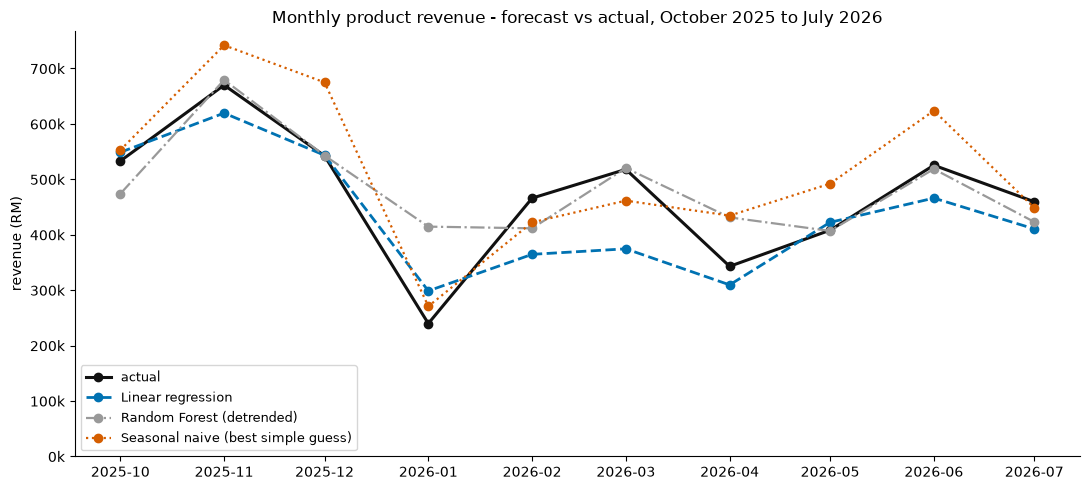

In [12]:
# Monthly totals: actual against the predictions, over the 10 fully covered test months
def summed(name):
    return (pd.DataFrame({"month": month_of, "forecast": np.asarray(predictions[name], float)})
              .groupby("month").forecast.sum().loc[covered])

x = pd.PeriodIndex(covered, freq="M").to_timestamp()
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(x, monthly.actual, color="#111", lw=2.2, marker="o", label="actual")
ax.plot(x, summed("Linear regression"), color="#0072B2", lw=2.0, ls="--", marker="o", label="Linear regression")
ax.plot(x, summed("Random Forest (detrended)"), color="#999", lw=1.6, ls="-.", marker="o", label="Random Forest (detrended)")
ax.plot(x, summed("Seasonal naive (lag 52)"), color="#D55E00", lw=1.6, ls=":", marker="o", label="Seasonal naive (best simple guess)")
ax.set_title("Monthly product revenue - forecast vs actual, October 2025 to July 2026")
ax.set_ylabel("revenue (RM)")
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
ax.legend(loc="lower left", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## What this run says

1. **A linear model on trend plus month is the best forecaster here.** Linear regression and
   Ridge score almost the same (weekly WAPE 27.5% and 27.8%) and beat every baseline, the best
   of which is 30.8%. Summed into months, the error falls to about 11%: weekly takings for a
   shop this size swing hard, and the monthly view is the fair read for planning.
2. **The models are closer together than the ranking suggests.** Everything from linear
   regression to the forests lands between 27.5% and 29.3%. They all capture the same trend and
   season; the week-to-week noise they cannot capture is most of what is left.
3. **Detrending does not rescue the forest this time.** Only two test weeks fall below the
   training floor, so the raw forest's floor costs it little, and the detrended versions score
   slightly worse (29.3% against 28.9%). The floor is still real: the raw forest never forecasts
   below RM 101,602 while the shop's quietest week took RM 40,630.
4. **`lag52` does not pay for itself.** The 52 training weeks it costs outweigh what a year-ago
   reading adds (28.4% against 27.8% for Ridge).
5. **The largest misses are January to March 2026**, when the product range changes: January is
   over-forecast by about a quarter, February and March under-forecast by a fifth or more. The
   training years contain no range change to learn from.

### Next

- Holt-Winters (ETS, damped trend) and ARIMA with Fourier terms, as the classical benchmarks.
- `TimeSeriesSplit` on the training block to tune `alpha` and the tree depths honestly.
- A range-change indicator for 2026. The shop knows in advance when its range changes, so it is
  legitimate information for a forecaster, but it must be declared in the report rather than
  slipped in.